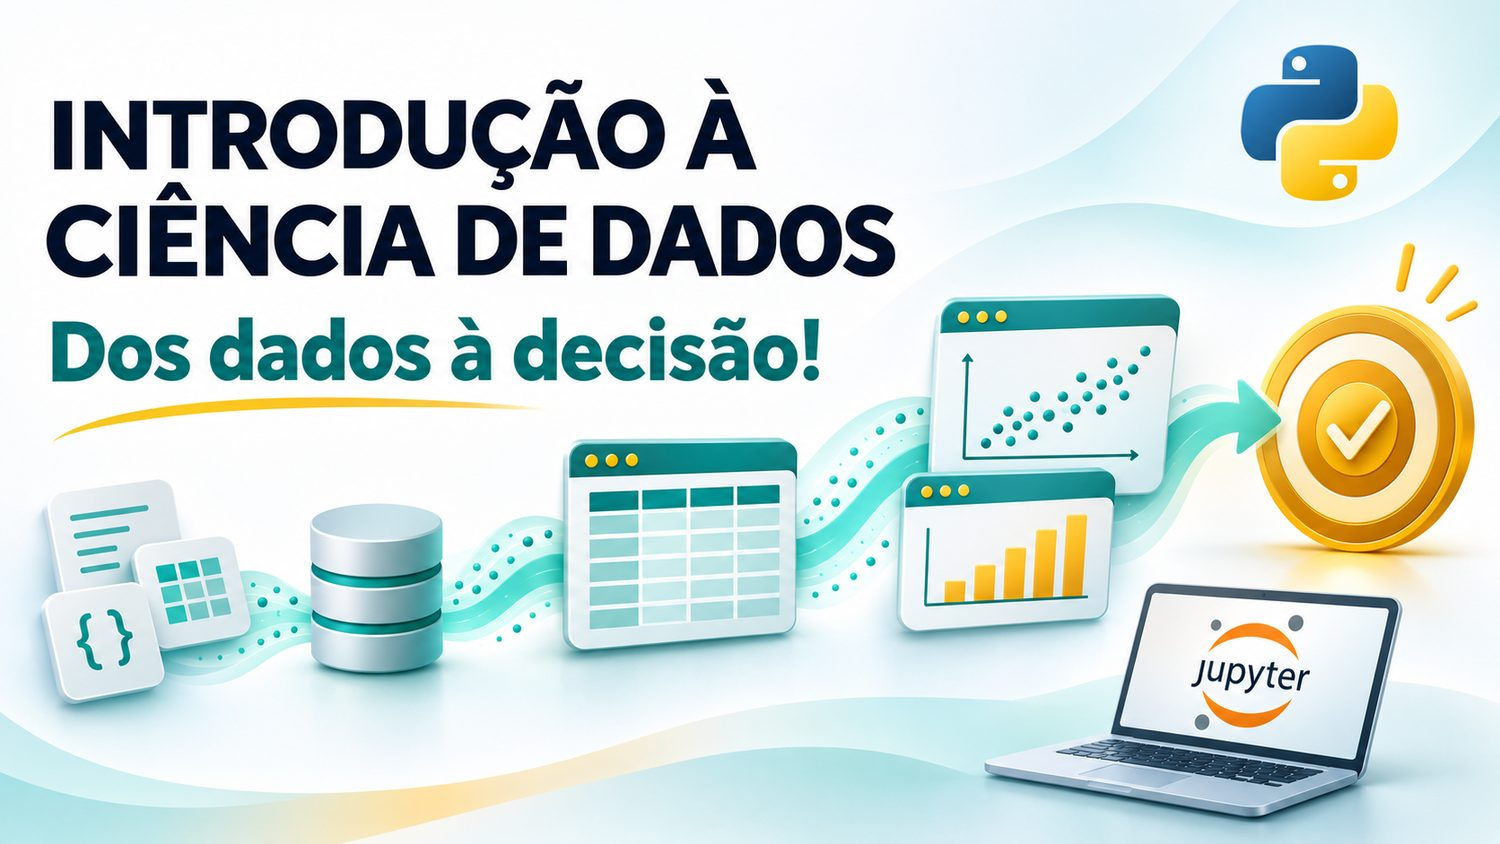

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_2_fontes_tipos_estruturas/01_Fontes_de_Dados.ipynb)

# Capítulo 1 – Fontes de dados

No módulo 1 os dados já estavam prontos numa tabela. Na prática, a primeira tarefa é ir buscá-los: decidir que fontes servem a pergunta, perceber o que cada uma consegue mostrar e juntá-las. Este capítulo trata dessa escolha, com um caso novo que acompanha todo o módulo.

> **Objetivos:** explicar porque um valor precisa de contexto; classificar fontes de dados por quem as gera e por que razão foram recolhidas; distinguir origem, forma de acesso e conteúdo; definir o alvo e o momento de uma previsão; escolher fontes para uma pergunta e saber o que verificar em cada uma; juntar várias fontes numa tabela.

**Pré-requisitos:** módulo 1. Noções de pandas (`merge`, `groupby`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## O que é um dado

Um **dado** é uma observação, uma medição ou uma descrição que alguém (ou alguma coisa) registou. Sozinho, um valor não diz nada: `187` pode ser uma temperatura, um preço ou um número de porta.

Um valor só ganha significado com quatro elementos de **contexto**.

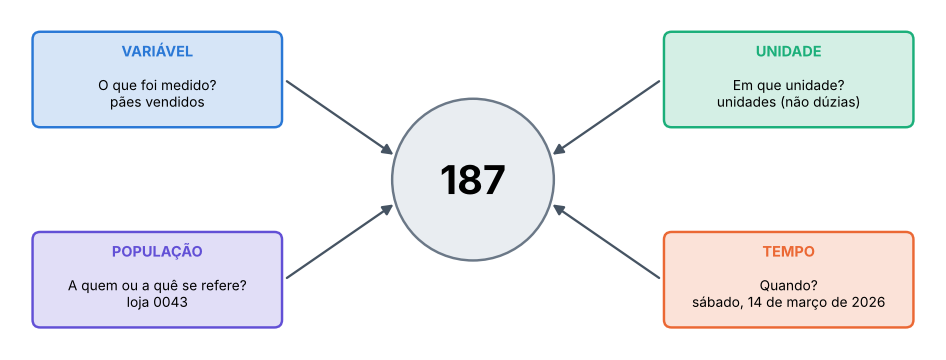

In [2]:
fig, ax = tela(12, 4.4, (11, 4))
ax.add_patch(Circle((6, 2.2), 1.05, fc="#e9edf1", ec="#6b7887", lw=1.6))
ax.set_aspect("equal")
ax.text(6, 2.2, "187", ha="center", va="center", fontsize=26, fontweight="bold")
contexto = [(0.3, 2.9, "VARIÁVEL", "O que foi medido?\npães vendidos", AZUL), (8.5, 2.9, "UNIDADE", "Em que unidade?\nunidades (não dúzias)", VERDE),
            (0.3, 0.3, "POPULAÇÃO", "A quem ou a quê se refere?\nloja 0043", VIOLETA), (8.5, 0.3, "TEMPO", "Quando?\nsábado, 14 de março de 2026", LARANJA)]
for x, y, nome, texto, cor in contexto:
    caixa(ax, x, y, 3.2, 1.2, "", cor)
    ax.text(x + 1.6, y + 0.9, nome, ha="center", fontweight="bold", color=cor, fontsize=9.5)
    ax.text(x + 1.6, y + 0.42, texto, ha="center", va="center", fontsize=9)
    seta(ax, (x + 3.25 if x < 6 else x - 0.05, y + 0.6), (5.0 if x < 6 else 7.0, 2.5 if y > 2 else 1.9))
plt.show()

Com o contexto, `187` passa a ser «a loja 0043 vendeu 187 pães no sábado, 14 de março de 2026». Falta um dos quatro elementos e o valor torna-se ambíguo: 187 dúzias são 2 244 pães.

Um **conjunto de dados** (*dataset*) é uma coleção organizada de observações, reunida **para um fim**. O fim importa: a mesma tabela de vendas pode ser excelente para a contabilidade e insuficiente para prever a procura.

## O caso deste módulo: quantos pães produzir?

Uma cadeia de padarias tem seis lojas. Todas as noites, a produção central decide quantos pães enviar a cada loja no dia seguinte. Se envia de mais, sobra pão; se envia de menos, o pão esgota e perdem-se vendas.

A cadeia quer **prever, para cada loja, se o pão vai esgotar amanhã**. Como no módulo 1, os dados são sintéticos.

Antes de procurar dados, é preciso fixar três coisas.

| Elemento | Definição neste caso |
| --- | --- |
| **Alvo** | Para cada loja, o pão esgota amanhã antes do fecho? (sim ou não) |
| **Momento da previsão** | Hoje às 18h00, quando se decide a produção |
| **Regra do rótulo** | Num dia passado, consideramos que o pão «esgotou» se a loja vendeu tudo o que recebeu |

A regra do rótulo é uma **convenção**: transforma o que se observou (pães vendidos e produzidos) na resposta que queremos prever. Outra regra seria possível (por exemplo, «esgotou antes das 17h00»), e daria outro conjunto de dados.

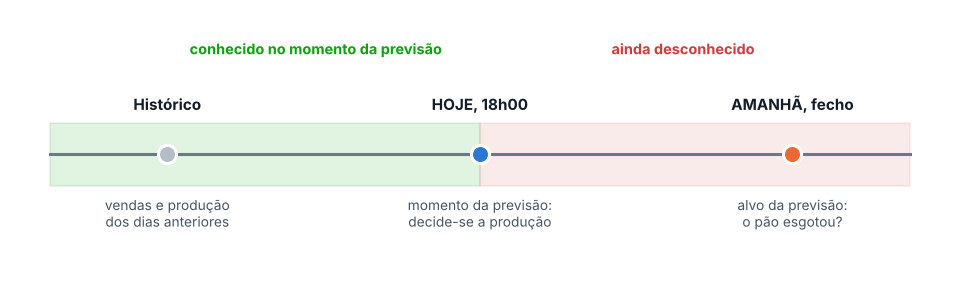

In [3]:
fig, ax = tela(12, 3.3, (11, 3.1))
ax.plot([0.5, 11.5], [1.5, 1.5], color="#6b7887", lw=2)
marcos = [(2.0, "Histórico", "vendas e produção\ndos dias anteriores", CINZA), (6.0, "HOJE, 18h00", "momento da previsão:\ndecide-se a produção", AZUL),
          (10.0, "AMANHÃ, fecho", "alvo da previsão:\no pão esgotou?", LARANJA)]
for x, nome, texto, cor in marcos:
    ax.scatter([x], [1.5], s=140, color=cor, zorder=3, edgecolor="white", linewidth=2)
    ax.text(x, 2.05, nome, ha="center", fontweight="bold", color=TINTA)
    ax.text(x, 0.75, texto, ha="center", va="center", fontsize=9, color="#465463")
ax.axvspan(0.5, 6.0, ymin=0.33, ymax=0.57, color=BOM, alpha=0.12)
ax.axvspan(6.0, 11.5, ymin=0.33, ymax=0.57, color=MAU, alpha=0.10)
ax.text(3.9, 2.75, "conhecido no momento da previsão", ha="center", color=BOM, fontsize=9.5, fontweight="bold")
ax.text(8.6, 2.75, "ainda desconhecido", ha="center", color=MAU, fontsize=9.5, fontweight="bold")
plt.show()

Tudo o que está à direita de «hoje, 18h00» só pode entrar na previsão se for, ele próprio, uma **previsão** (a meteorologia de amanhã) ou um **plano** (um evento já anunciado). É a regra da fuga de informação do módulo 1, capítulo 2.

## Classificar as fontes

Há duas perguntas úteis sobre qualquer fonte.

**Quem ou o que gerou os dados?**

- **Geradas por pessoas:** inquéritos, publicações, relatórios escritos, registos de negócio preenchidos à mão.
- **Geradas por máquinas:** sensores, câmaras, registos automáticos de sistemas (*logs*).

**Para que foram recolhidos?**

- **Fonte primária:** recolhidos de propósito para este estudo.
- **Fonte secundária:** recolhidos para outro fim e reaproveitados.

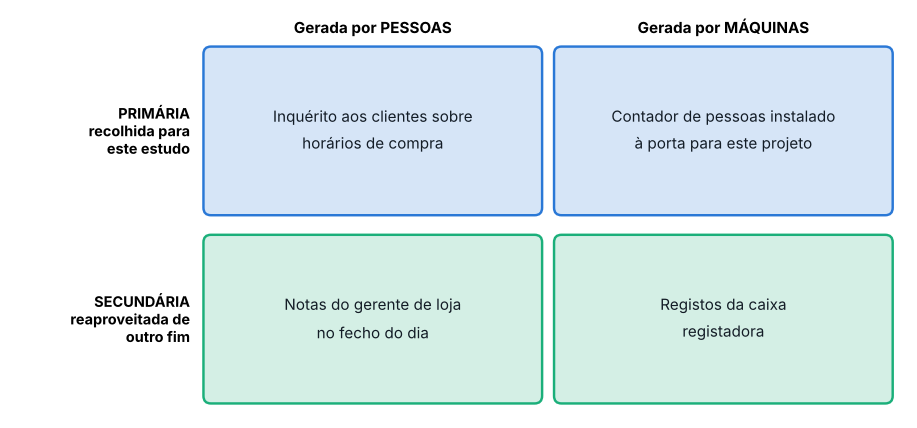

In [4]:
fig, ax = tela(12, 5.4, (10.5, 4.8))
quadrantes = [(2.6, 2.7, "Inquérito aos clientes sobre\nhorários de compra", AZUL), (7.3, 2.7, "Contador de pessoas instalado\nà porta para este projeto", AZUL),
              (2.6, 0.2, "Notas do gerente de loja\nno fecho do dia", VERDE), (7.3, 0.2, "Registos da caixa\nregistadora", VERDE)]
for x, y, texto, cor in quadrantes:
    caixa(ax, x, y, 4.5, 2.2, texto, cor, 10)
ax.text(4.85, 5.1, "Gerada por PESSOAS", ha="center", fontweight="bold")
ax.text(9.55, 5.1, "Gerada por MÁQUINAS", ha="center", fontweight="bold")
ax.text(2.4, 3.8, "PRIMÁRIA\nrecolhida para\neste estudo", ha="right", va="center", fontweight="bold", fontsize=9.5)
ax.text(2.4, 1.3, "SECUNDÁRIA\nreaproveitada de\noutro fim", ha="right", va="center", fontweight="bold", fontsize=9.5)
plt.show()

Nenhum quadrante é melhor do que os outros. Cada um tem um defeito típico:

| Tipo de fonte | Vantagem | Defeito típico |
| --- | --- | --- |
| Pessoas | Regista motivos, opiniões e contexto | Critérios variam de pessoa para pessoa; há esquecimentos |
| Máquinas | Volume, regularidade, hora exata | Avarias silenciosas, descalibração; só mede o que foi programado |
| Primária | Mede exatamente o que a pergunta pede | Cara e demorada |
| Secundária | Já existe e é barata | Foi definida para outro fim: pode não medir o que precisamos |

### Três famílias de fontes externas

- **Dados abertos:** publicados por entidades públicas ou privadas para consulta e reutilização, segundo condições declaradas (uma licença). Exemplos: estatísticas oficiais, observações meteorológicas, horários de transportes.
- **Redes sociais:** publicações, imagens e interações. Só mostram quem participa: uma zona com poucos utilizadores quase não aparece, mesmo que lá aconteça muita coisa.
- **Conjuntos de dados de referência:** coleções partilhadas, usadas para aprender ou para comparar métodos. São úteis para treinar e quase nunca respondem a uma pergunta real.

### Dados multimodais

Uma fonte é **multimodal** quando junta várias modalidades: texto, imagem, áudio, medições numéricas. Uma reclamação de um cliente com uma fotografia e a hora da compra é multimodal.

### Origem, acesso e conteúdo são coisas diferentes

Há três formas habituais de **aceder** a dados: ficheiros, bases de dados e APIs (serviços a que um programa faz pedidos). É fácil confundir a forma de acesso com a origem ou com o conteúdo. São três propriedades independentes:

| Propriedade | Pergunta | Exemplo |
| --- | --- | --- |
| **Origem** | Quem produziu os dados, e como? | Caixas registadoras das lojas |
| **Acesso** | Como chegam até nós? | Um ficheiro CSV exportado todas as noites |
| **Conteúdo** | O que contêm? | Uma linha por loja e por dia, com pães produzidos e vendidos |

Os mesmos dados de vendas podiam chegar por uma API ou por uma base de dados sem que a origem ou o conteúdo mudassem. E um ficheiro CSV bem formatado não torna fiáveis os dados que lá estão.

## Escolher as fontes para o nosso caso

Que informação ajudaria a prever se o pão esgota amanhã? A procura depende do dia da semana, do tempo e do que acontece perto de cada loja.

| Fonte possível | Dados que fornece | O que verificar antes de usar |
| --- | --- | --- |
| Registos das caixas | Pães produzidos e vendidos, por loja e por dia | Cobertura (todas as lojas? todos os dias?), falhas, definição de «vendido» |
| Serviço de previsão meteorológica | Chuva prevista para amanhã | Hora a que a previsão foi emitida; zona a que se refere |
| Agenda municipal de eventos | Eventos, com data e zona | Atualizações de última hora; correspondência entre zonas e lojas |
| Cadastro das lojas | Identificador, zona e produção habitual de cada loja | Identificadores estáveis; definições atualizadas |

A função seguinte gera as quatro fontes.

In [5]:
def gerar_padaria(semente=7):
    """Gera os dados de uma cadeia fictícia de padarias (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    lojas = pd.DataFrame({
        "loja_id": ["0041", "0042", "0043", "0107", "0212", "0305"],
        "zona": ["Baixa", "Baixa", "Ribeira", "Estação", "Universidade", "Mercado"],
        "producao_habitual": [320, 260, 180, 400, 220, 300]})
    dias = pd.date_range("2026-03-02", periods=84, freq="D")          # doze semanas, de segunda a domingo
    chuva = np.where(rng.random(84) < 0.35, rng.gamma(2.0, 3.0, 84).round(1), 0.0)
    meteo = pd.DataFrame({"data": dias, "chuva_mm": chuva})
    eventos = pd.DataFrame({
        "data": pd.to_datetime(["2026-03-14", "2026-03-28", "2026-04-11", "2026-04-25", "2026-05-09", "2026-05-16"]),
        "zona": ["Ribeira", "Mercado", "Baixa", "Baixa", "Ribeira", "Universidade"],
        "evento": ["Feira do livro", "Mercado de produtores", "Maratona", "Desfile", "Festival de rua", "Dia aberto"]})
    fator_dia = [0.95, 0.90, 0.92, 0.97, 1.06, 1.20, 1.08]            # segunda a domingo
    linhas = []
    for loja in lojas.itertuples():
        for dia, mm in zip(dias, chuva):
            ha_evento = ((eventos["data"] == dia) & (eventos["zona"] == loja.zona)).any()
            procura = (loja.producao_habitual * 0.9 * fator_dia[dia.dayofweek] * (1 - 0.012 * mm)
                       * (1.35 if ha_evento else 1.0) * rng.normal(1.0, 0.07))
            linhas.append((loja.loja_id, dia, loja.producao_habitual, int(min(round(procura), loja.producao_habitual))))
    vendas = pd.DataFrame(linhas, columns=["loja_id", "data", "produzidos", "vendidos"])
    return lojas, vendas, meteo, eventos


lojas, vendas, meteo, eventos = gerar_padaria()
vendas.head()

,loja_id,data,produzidos,vendidos
0,0041,2026-03-02,320,260
1,0041,2026-03-03,320,250
2,0041,2026-03-04,320,290
3,0041,2026-03-05,320,253
4,0041,2026-03-06,320,253


In [6]:
print("lojas:", lojas.shape, "| vendas:", vendas.shape, "| meteo:", meteo.shape, "| eventos:", eventos.shape)
lojas

lojas: (6, 3) | vendas: (504, 4) | meteo: (84, 2) | eventos: (6, 3)


,loja_id,zona,producao_habitual
0,0041,Baixa,320
1,0042,Baixa,260
2,0043,Ribeira,180
3,0107,Estação,400
4,0212,Universidade,220
5,0305,Mercado,300


In [7]:
eventos

,data,zona,evento
0,2026-03-14,Ribeira,Feira do livro
1,2026-03-28,Mercado,Mercado de produtores
2,2026-04-11,Baixa,Maratona
3,2026-04-25,Baixa,Desfile
4,2026-05-09,Ribeira,Festival de rua
5,2026-05-16,Universidade,Dia aberto


### Juntar as fontes

As quatro tabelas só se tornam um conjunto de dados quando as ligamos. Para isso precisam de **chaves**: colunas com o mesmo significado nas duas tabelas.

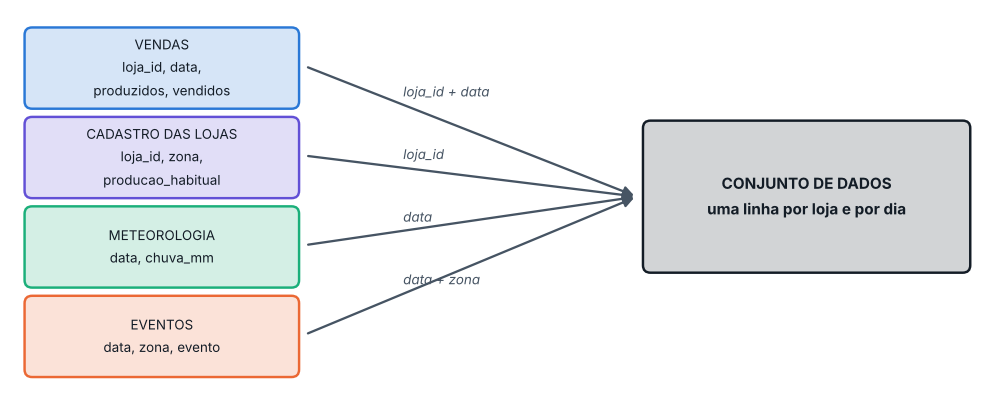

In [8]:
fig, ax = tela(13, 5, (11.5, 4.4))
fontes = [(0.2, 3.7, "VENDAS\nloja_id, data,\nproduzidos, vendidos", AZUL), (0.2, 2.5, "CADASTRO DAS LOJAS\nloja_id, zona,\nproducao_habitual", VIOLETA),
          (0.2, 1.3, "METEOROLOGIA\ndata, chuva_mm", VERDE), (0.2, 0.1, "EVENTOS\ndata, zona, evento", LARANJA)]
for x, y, texto, cor in fontes:
    caixa(ax, x, y, 3.6, 1.05, texto, cor, 8.8)
chaves = [(4.25, "loja_id + data"), (3.05, "loja_id"), (1.85, "data"), (0.65, "data + zona")]
for y, chave in chaves:
    seta(ax, (3.9, y), (8.3, 2.5))
    ax.text(5.2, y + (2.5 - y) * 0.3 + 0.12, chave, fontsize=8.8, style="italic", color="#465463")
caixa(ax, 8.4, 1.5, 4.3, 2.0, "CONJUNTO DE DADOS\numa linha por loja e por dia", TINTA, 10, True)
plt.show()

In [9]:
dados = (vendas
         .merge(lojas[["loja_id", "zona"]], on="loja_id", how="left")
         .merge(meteo, on="data", how="left")
         .merge(eventos, on=["data", "zona"], how="left"))
dados["ha_evento"] = dados["evento"].notna()
dados["esgotou"] = dados["vendidos"] == dados["produzidos"]        # a regra do rótulo
dados["dia_semana"] = dados["data"].dt.dayofweek.map(dict(enumerate(["seg", "ter", "qua", "qui", "sex", "sáb", "dom"])))

print(f"{len(vendas)} linhas antes da junção, {len(dados)} depois")
dados[dados["ha_evento"]].head()

504 linhas antes da junção, 504 depois


,loja_id,data,produzidos,vendidos,zona,chuva_mm,evento,ha_evento,esgotou,dia_semana
40,0041,2026-04-11,320,320,Baixa,1.2,Maratona,True,True,sáb
54,0041,2026-04-25,320,320,Baixa,9.7,Desfile,True,True,sáb
124,0042,2026-04-11,260,260,Baixa,1.2,Maratona,True,True,sáb
138,0042,2026-04-25,260,260,Baixa,9.7,Desfile,True,True,sáb
180,0043,2026-03-14,180,180,Ribeira,7.2,Feira do livro,True,True,sáb


Depois de cada junção, confirma sempre que o número de linhas é o esperado. Se aumentou, há chaves repetidas numa das tabelas; se há muitos valores em falta nas colunas novas, as chaves não coincidem (por exemplo, `"0043"` numa tabela e `43` na outra, que é o tema do próximo capítulo).

### As variáveis do conjunto de dados

| Variável | Exemplo | Significado | Conhecida hoje às 18h00? |
| --- | --- | --- | --- |
| `loja_id` | `"0043"` | Identificador da loja | Sim |
| `data` | 2026-03-14 | Dia a que a linha se refere | Sim |
| `dia_semana` | sáb | Dia da semana | Sim |
| `produzidos` | 180 | Pães enviados para a loja | Sim (é a decisão) |
| `chuva_mm` | 2.4 | Chuva nesse dia | Só a **previsão** |
| `ha_evento` | `True` | Há um evento na zona da loja | Sim, se já estiver anunciado |
| `vendidos` | 180 | Pães vendidos | **Não** |
| `esgotou` | `True` | Rótulo: vendeu tudo o que recebeu | **Não** (é o que queremos prever) |

Há um pormenor importante na linha da chuva. No histórico temos a chuva que **caiu**; amanhã só teremos a chuva **prevista**. Um modelo treinado com a chuva observada vai parecer melhor do que será na prática, porque as previsões meteorológicas erram. O ideal é guardar as previsões tal como foram emitidas e treinar com elas.

### As fontes escolhidas servem a pergunta?

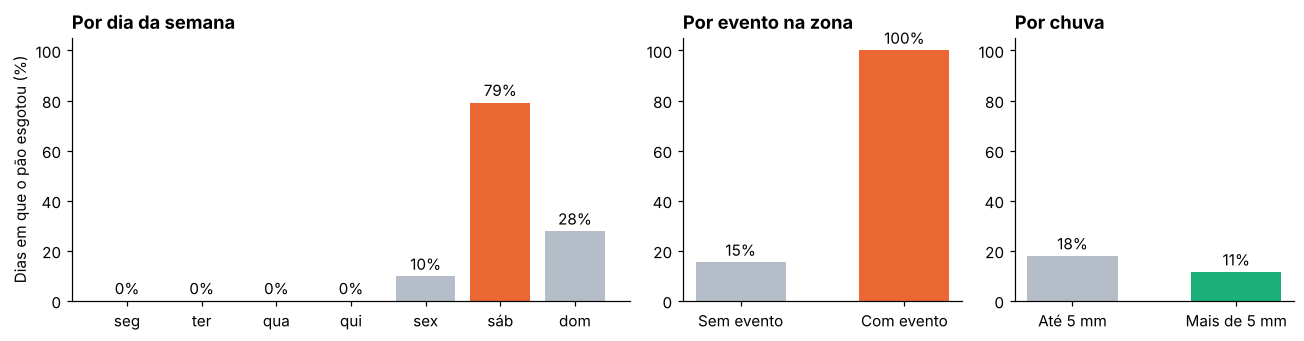

In [10]:
ordem = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
por_dia = dados.groupby("dia_semana")["esgotou"].mean().loc[ordem] * 100
por_evento = dados.groupby("ha_evento")["esgotou"].mean() * 100
por_chuva = dados.groupby(dados["chuva_mm"] > 5)["esgotou"].mean() * 100

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw={"width_ratios": [2, 1, 1]})
b = ax1.bar(por_dia.index, por_dia, color=[LARANJA if v > 50 else CINZA for v in por_dia])
ax1.bar_label(b, fmt="%.0f%%", padding=2)
ax1.set_title("Por dia da semana")
ax1.set_ylabel("Dias em que o pão esgotou (%)")
b = ax2.bar(["Sem evento", "Com evento"], por_evento, color=[CINZA, LARANJA], width=0.55)
ax2.bar_label(b, fmt="%.0f%%", padding=2)
ax2.set_title("Por evento na zona")
b = ax3.bar(["Até 5 mm", "Mais de 5 mm"], por_chuva, color=[CINZA, VERDE], width=0.55)
ax3.bar_label(b, fmt="%.0f%%", padding=2)
ax3.set_title("Por chuva")
for eixo in (ax1, ax2, ax3):
    eixo.set_ylim(0, 105)
plt.tight_layout()
plt.show()

As três fontes externas trazem informação: o pão esgota sobretudo ao sábado, esgotou em todos os dias com evento na zona e esgota menos em dias de muita chuva. Uma fonte é útil quando **mede alguma coisa relevante para a pergunta**, e isto verifica-se com os dados, antes de construir qualquer modelo.

## Cinco verificações antes de confiar numa fonte

| Verificação | Pergunta | Exemplo de problema |
| --- | --- | --- |
| **Proveniência** | Quem produziu os dados, como e porquê? | Uma agenda de eventos compilada por voluntários, sem responsável |
| **Cobertura** | Quem ou o que está incluído, e quem fica de fora? | A loja mais recente só tem dois meses de registos |
| **Documentação** | Há uma descrição das variáveis, das unidades e das regras? | Não se sabe se «vendidos» inclui pão oferecido no fecho |
| **Atualidade** | A que período se referem, e com que atraso chegam? | A previsão meteorológica disponível às 18h00 foi emitida às 6h00 |
| **Uso permitido** | A licença e a lei permitem este uso? | Dados de clientes recolhidos para faturação, usados para outro fim |

> **Acesso fácil não significa dados corretos nem representativos.** O ficheiro que se descarrega com um clique pode ser o menos adequado à pergunta.

## Exercícios

### `Exercício 1` – Classificar fontes

Classifica cada fonte como gerada por pessoas ou por máquinas, e como primária ou secundária para o projeto das padarias:

1. Temperatura registada de hora a hora pelo forno de cada loja.
2. Um questionário, criado pela equipa do projeto, em que os gerentes indicam a que horas o pão esgotou.
3. Publicações de clientes nas redes sociais a queixarem-se de falta de pão.
4. As faturas dos fornecedores de farinha.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Máquinas; secundária (o forno regista a temperatura para controlo da cozedura).
2. Pessoas; primária (foi criado para este projeto).
3. Pessoas; secundária. Atenção à cobertura: só aparece quem publica.
4. Pessoas ou sistemas de faturação, conforme a empresa; secundária.

</details>

### `Exercício 2` – Origem, acesso ou conteúdo?

Indica a que propriedade se refere cada frase:

1. «Os dados chegam por uma API que devolve JSON.»
2. «As contagens vêm de um sensor de infravermelhos instalado à porta.»
3. «Cada registo tem a hora, o número de entradas e o número de saídas.»
4. «A autarquia publica o ficheiro no seu portal de dados abertos.»

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Acesso.
2. Origem.
3. Conteúdo.
4. Acesso (e uma pista sobre o uso permitido: há que ler a licença). A origem é quem recolheu os dados que a autarquia publica.

</details>

### `Exercício 3` – O que se sabe às 18h00?

A equipa propõe acrescentar estas variáveis ao conjunto de dados. Quais podem ser usadas na previsão feita hoje às 18h00 para amanhã?

`hora_a_que_esgotou` · `vendidos_ontem` · `chuva_observada_amanha` · `feriado_amanha` · `sobras_de_amanha` · `vendidos_mesmo_dia_semana_passada`

<details>
<summary><b>Ver uma solução possível</b></summary>

Podem ser usadas: `vendidos_ontem`, `feriado_amanha` (o calendário é conhecido) e `vendidos_mesmo_dia_semana_passada`.

Não podem: `hora_a_que_esgotou` e `sobras_de_amanha` (só existem depois do facto) e `chuva_observada_amanha` (hoje só há a previsão).

</details>

### `Exercício 4` – Uma junção que corre mal

A célula seguinte acrescenta uma linha repetida à tabela de eventos (o mesmo evento registado duas vezes com nomes diferentes). Refaz a junção e descobre o que acontece ao número de linhas. Como o detetarias num projeto real?

In [11]:
eventos_com_repeticao = pd.concat([eventos, pd.DataFrame({"data": pd.to_datetime(["2026-03-14"]), "zona": ["Ribeira"],
                                                          "evento": ["Feira do Livro da Ribeira"]})], ignore_index=True)
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
teste = vendas.merge(lojas[["loja_id", "zona"]], on="loja_id").merge(eventos_com_repeticao, on=["data", "zona"], how="left")
print(len(vendas), "→", len(teste))
print(teste[teste.duplicated(["loja_id", "data"], keep=False)])
```

A tabela ganha uma linha: o dia 14 de março da loja da Ribeira aparece duas vezes, e as suas vendas passariam a contar a dobrar. Deteta-se comparando o número de linhas antes e depois, ou pedindo ao pandas que valide a junção: `merge(..., validate="many_to_one")` dá erro quando a tabela da direita tem chaves repetidas.

</details>

## Verifica o que aprendeste

- [ ] Sei indicar os quatro elementos de contexto de um valor.
- [ ] Sei distinguir fontes geradas por pessoas e por máquinas, primárias e secundárias, e o defeito típico de cada uma.
- [ ] Sei distinguir origem, acesso e conteúdo.
- [ ] Sei definir o alvo, o momento da previsão e a regra do rótulo.
- [ ] Sei juntar tabelas por chaves e verificar se a junção correu bem.
- [ ] Sei as cinco verificações a fazer antes de confiar numa fonte.

## Leitura recomendada

- https://pandas.pydata.org/docs/user_guide/merging.html
- https://en.wikipedia.org/wiki/Open_data
- https://en.wikipedia.org/wiki/Secondary_data